In [ ]:
import sys
import os
base_dir = r"C:\Users\acostamendoza\projects\distance-project"
data_dir = r"D:\data-distance-coding-project\processed-data"
sys.path.append(base_dir)
from src.RadialExperiment import RadialDevice, RadialPlots, RadialSummaries
import numpy as np
import matplotlib.pyplot as plt
import pickle
from scipy.optimize import curve_fit

%load_ext autoreload
%autoreload 2

mouse_name = 'SAM041'
record_date = '251128'
experiment_name = 'tiling_3_120um'

data_dir = os.path.join(data_dir, f'{record_date}_{mouse_name}_{experiment_name}')
summ_name = f'{record_date}_{mouse_name}_{experiment_name}_summaries.pkl'
summ_dir = os.path.join(data_dir, summ_name)

try:
    with open(summ_dir, 'rb') as f:
        summ = pickle.load(f)
        print(f"File {summ_dir} imported.")
except FileNotFoundError:
    print(f"The file {summ_dir} does not exist.")

stats_df = summ.R.analyze_session_stats()

File D:\data-distance-coding-project\processed-data\251128_SAM041_tiling_3_120um\251128_SAM041_tiling_3_120um_summaries.pkl imported.


In [4]:
R = summ.R
from scipy.optimize import curve_fit

In [44]:
def identify_cells(session_stats, threshold):

    reliable = session_stats[
        (session_stats['monocular'].apply(lambda x: x['reliable']) == True) &
        (session_stats['binocular'].apply(lambda x: x['reliable']) == True) &
        ((session_stats['monocular'].apply(lambda x: x['reliable_corr']) >= threshold) |
        (session_stats['binocular'].apply(lambda x: x['reliable_corr']) >= threshold))
    ]['cell_id'].values

    # Filter for cells that are in the reliable set AND meet the monocular/binocular criteria
    monocular_only = session_stats[
        (session_stats['cell_id'].isin(reliable)) &
        (session_stats['monocular'].apply(lambda x: x['bootstrap_pvalue']) < 0.05) &
        (session_stats['binocular'].apply(lambda x: x['bootstrap_pvalue']) > 0.05)
    ]['cell_id'].values

    binocular_only = session_stats[
        (session_stats['cell_id'].isin(reliable)) &
        (session_stats['monocular'].apply(lambda x: x['bootstrap_pvalue']) > 0.05) &
        (session_stats['binocular'].apply(lambda x: x['bootstrap_pvalue']) < 0.05)
    ]['cell_id'].values

    both = session_stats[
        (session_stats['cell_id'].isin(reliable)) &
        (session_stats['monocular'].apply(lambda x: x['bootstrap_pvalue']) < 0.05) &
        (session_stats['binocular'].apply(lambda x: x['bootstrap_pvalue']) < 0.05)
    ]['cell_id'].values

    none = session_stats[
        (session_stats['cell_id'].isin(reliable)) &
        (session_stats['monocular'].apply(lambda x: x['bootstrap_pvalue']) > 0.05) &
        (session_stats['binocular'].apply(lambda x: x['bootstrap_pvalue']) > 0.05)
    ]['cell_id'].values

    return reliable, monocular_only, binocular_only, both, none

In [72]:
def tuning_curve(position, amplitude, rf_center, width, baseline):
    """Gaussian tuning curve: response as function of stimulus position."""
    return amplitude * np.exp(-((position - rf_center)**2) / (2 * width**2)) + baseline

def fit_response(mean_response):
    """
    Fit tuning curve to one neuron.
    
    Returns: (amplitude, rf_center, width, baseline, noise_std)
    """

    # Initial guesses
    baseline = np.min(mean_response)
    amplitude = np.max(mean_response) - baseline
    rf_center = R.angle_range[np.argmax(mean_response)]
    width = 10
    
    # Fit
    try:
        params, _ = curve_fit(
            tuning_curve, R.angle_range, mean_response,
            p0=[amplitude, rf_center, width, baseline],
            bounds=([0, -40, 1, -np.inf], [np.inf, 80, 60, np.inf])
        )
    except:
        params = [amplitude, rf_center, width, baseline]
    
    # Estimate noise from residuals
    predicted = tuning_curve(R.angle_range, *params)
    noise_std = np.std(mean_response - predicted)
    
    return (*params, noise_std)

def plot_fit(mean_response):

    params = fit_response(mean_response)
    predicted = tuning_curve(R.angle_range, *params[:4])
    plt.plot(R.angle_range, mean_response, label='Mean response')
    plt.plot(R.angle_range, predicted, label='Fitted curve')
    plt.legend()
    plt.show()

def log_likelihood(response_vector, candidate_position, neuron_params):
    """Gaussian log-likelihood of observing response given position."""
    ll = 0.0
    for i, (amp, rf, width, base, noise) in enumerate(neuron_params):
        expected = tuning_curve(candidate_position, amp, rf, width, base)
        ll -= (response_vector[i] - expected)**2 / (2 * noise**2)
    return ll

def decode(response_vector, neuron_params):
    """Find position that maximizes likelihood."""
    positions = R.angle_range
    ll_values = [log_likelihood(response_vector, p, neuron_params) for p in positions]
    return positions[np.argmax(ll_values)]

In [125]:
def get_train_test_idxs(train_pctg):
    
    trial_idxs = R.get_condition_trials(monocular=None, distance=None)
    total_trials = len(R.distance_sequence)

    trial_idxs = np.random.permutation(trial_idxs)
    split_point = int(train_pctg * len(trial_idxs))

    # Create boolean masks
    train_mask = np.isin(np.arange(len(trial_idxs)), trial_idxs[:split_point])
    test_mask = np.isin(np.arange(len(trial_idxs)), trial_idxs[split_point:])

    return train_mask, train_idxs, test_mask, test_idxs

def get_train_mean_responses(cell, train_mask):
    all_traces = R.get_all_traces(cell, distance = None, monocular = None, mean_trace=False)
    return np.mean(all_traces[train_mask, :], axis=0)

def get_test_trial_responses(cells_to_include, test_idx):

    test_responses = np.array([
        R.get_repeat_trace(cell, test_idx)
        for cell in cells_to_include
    ])

    return test_responses


def fit_all_neurons(cells_to_include, train_mask):

    neuron_params = []

    for cell in cells_to_include:
        train_responses = get_train_mean_responses(cell, train_mask)
        neuron_params.append(fit_response(train_responses))

    return neuron_params

def decode_trajectory(cells_to_include, neuron_params, test_idx):

    test_responses = get_test_trial_responses(cells_to_include, test_idx)

    decoded_positions = []
    for i, angle in enumerate(R.angle_range):
        decoded_positions.append(decode(test_responses[:, i], neuron_params))
    
    return decoded_positions


reliable_cells = identify_cells(stats_df, 0.85)[0]

# Perform k-fold cross-validation
k_folds = 5
all_decoded_positions = []
all_test_idxs = []

for fold in range(k_folds):
    print(f'\n=== Fold {fold + 1}/{k_folds} ===')
    
    # Get train/test split for this fold
    train_mask, train_idxs, test_mask, test_idxs = get_train_test_idxs(0.9)
    
    # Fit neurons on training data
    neuron_params = fit_all_neurons(reliable_cells, train_mask)
    
    # Decode test trials
    fold_decoded_positions = []
    for i in range(len(test_idxs)):
        print(f'Decoding trial {i + 1} of {len(test_idxs)}, index is {test_idxs[i]}')
        fold_decoded_positions.append(decode_trajectory(reliable_cells, neuron_params, test_idxs[i]))
    
    all_decoded_positions.extend(fold_decoded_positions)
    all_test_idxs.extend(test_idxs)

print(f'\nTotal decoded trials: {len(all_decoded_positions)}')

# train_mask, train_idxs, test_mask, test_idxs = get_train_test_idxs(0.9)
# neuron_params = fit_all_neurons(reliable_cells, train_mask)

# decoded_positions = []
# for i in range(len(test_idxs)):
#     print(f'Decoding trial {i} of {len(test_idxs)}, index is {test_idxs[i]}')
#     decoded_positions.append(decode_trajectory(reliable_cells, neuron_params, test_idxs[i]))


=== Fold 1/5 ===


Decoding trial 1 of 10, index is 12
Decoding trial 2 of 10, index is 42
Decoding trial 3 of 10, index is 38
Decoding trial 4 of 10, index is 104
Decoding trial 5 of 10, index is 40
Decoding trial 6 of 10, index is 9
Decoding trial 7 of 10, index is 98
Decoding trial 8 of 10, index is 33
Decoding trial 9 of 10, index is 65
Decoding trial 10 of 10, index is 93

=== Fold 2/5 ===
Decoding trial 1 of 10, index is 12
Decoding trial 2 of 10, index is 42
Decoding trial 3 of 10, index is 38
Decoding trial 4 of 10, index is 104
Decoding trial 5 of 10, index is 40
Decoding trial 6 of 10, index is 9
Decoding trial 7 of 10, index is 98
Decoding trial 8 of 10, index is 33
Decoding trial 9 of 10, index is 65
Decoding trial 10 of 10, index is 93

=== Fold 3/5 ===
Decoding trial 1 of 10, index is 12
Decoding trial 2 of 10, index is 42
Decoding trial 3 of 10, index is 38
Decoding trial 4 of 10, index is 104
Decoding trial 5 of 10, index is 40
Decoding trial 6 of 10, index is 9
Decoding trial 7 of 10, in

In [ ]:
"""
Decoder Evaluation Functions
============================

Functions to evaluate how well the decoder is performing.
"""

import numpy as np
import matplotlib.pyplot as plt


def evaluate_decoder(actual, decoded, position_bins=10):
    """
    Compute summary metrics for decoder performance.
    
    Parameters
    ----------
    actual : array (n_trials, n_timepoints)
        Ground truth positions
    decoded : array (n_trials, n_timepoints)
        Decoded positions
    
    Returns
    -------
    metrics : dict
    """
    errors = decoded - actual
    
    metrics = {
        'mae': np.mean(np.abs(errors)),
        'rmse': np.sqrt(np.mean(errors**2)),
        'bias': np.mean(errors),  # systematic over/under estimation
        'correlation': np.corrcoef(actual.flatten(), decoded.flatten())[0, 1],
        'std': np.std(errors),    # variability of errors
    }
    
    return metrics


def plot_decoder_performance(actual, decoded, n_example_trials=3):
    """
    Comprehensive visualization of decoder performance.
    
    Parameters
    ----------
    actual : array (n_trials, n_timepoints)
    decoded : array (n_trials, n_timepoints)
    n_example_trials : int
        Number of example trials to show
    """
    errors = decoded - actual
    metrics = evaluate_decoder(actual, decoded)
    
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    
    # ----- Plot 1: Scatter (decoded vs actual) -----
    ax = axes[0, 0]
    ax.scatter(actual.flatten(), decoded.flatten(), alpha=0.3, s=5)
    
    # Diagonal line (perfect decoding)
    lims = [min(actual.min(), decoded.min()), max(actual.max(), decoded.max())]
    ax.plot(lims, lims, 'r--', linewidth=2, label='Perfect')
    
    ax.set_xlabel('Actual position (°)')
    ax.set_ylabel('Decoded position (°)')
    ax.set_title(f'Decoded vs Actual (r = {metrics["correlation"]:.3f})')
    ax.legend()
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)

    # ----- Plot 2: Mean decoded trajectory with error bars -----
    ax = axes[0, 1]
    
    # Compute mean and SEM across trials
    mean_actual = np.mean(actual, axis=0)
    mean_decoded = np.mean(decoded, axis=0)
    sem_decoded = np.std(decoded, axis=0) / np.sqrt(decoded.shape[0])
    
    time_points = np.arange(len(mean_actual))
    
    ax.plot(time_points, mean_actual, 'k-', linewidth=2, label='Actual', alpha=0.7)
    ax.plot(time_points, mean_decoded, color='blue', linewidth=2, label='Decoded')
    ax.fill_between(time_points, 
                    mean_decoded - sem_decoded, 
                    mean_decoded + sem_decoded, 
                    alpha=0.3, 
                    color='blue')
    
    ax.set_xlabel('Time (frames)')
    ax.set_ylabel('Position (°)')
    ax.set_title('Mean Trajectory (across trials)')
    ax.legend()
    ax.grid(True, alpha=0.3)
    

    # ----- Plot 4: Error histogram -----
    ax = axes[1, 0]
    ax.hist(errors.flatten(), bins=50, edgecolor='black', alpha=0.7)
    ax.axvline(0, color='r', linestyle='--', linewidth=2)
    ax.axvline(metrics['bias'], color='orange', linestyle='-', linewidth=2, label=f'Bias = {metrics["bias"]:.2f}°')
    
    ax.set_xlabel('Error (°)')
    ax.set_ylabel('Count')
    ax.set_title(f'Error Distribution (MAE = {metrics["mae"]:.2f}°, RMSE = {metrics["rmse"]:.2f}°)')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # ----- Plot 3: Error vs position -----
    ax = axes[1, 1]
    
    # Bin by actual position
    pos_flat = actual.flatten()
    err_flat = errors.flatten()
    
    bins = np.linspace(pos_flat.min(), pos_flat.max(), 15)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    bin_indices = np.digitize(pos_flat, bins) - 1
    
    mean_err = []
    std_err = []
    for i in range(len(bins) - 1):
        mask = bin_indices == i
        if mask.sum() > 0:
            mean_err.append(np.mean(np.abs(err_flat[mask])))
            std_err.append(np.std(err_flat[mask]))
        else:
            mean_err.append(np.nan)
            std_err.append(np.nan)
    
    ax.errorbar(bin_centers, mean_err, yerr=std_err, fmt='o-', capsize=3)
    ax.axhline(metrics['mae'], color='r', linestyle='--', alpha=0.5, label=f'Overall MAE = {metrics["mae"]:.2f}°')
    
    ax.set_xlabel('Actual position (°)')
    ax.set_ylabel('Absolute error (°)')
    ax.set_title('Error vs Position')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    return fig, metrics


def print_metrics(metrics):
    """Pretty print the metrics."""
    print("=" * 40)
    print("DECODER PERFORMANCE")
    print("=" * 40)
    print(f"  Mean Absolute Error:  {metrics['mae']:.2f}°")
    print(f"  RMSE:                 {metrics['rmse']:.2f}°")
    print(f"  Bias:                 {metrics['bias']:.2f}°")
    print(f"  Correlation:          {metrics['correlation']:.3f}")
    print(f"  Error Std:            {metrics['std']:.2f}°")
    print("=" * 40)


# =============================================================================
# DEMO
# =============================================================================

(10, 59)
(10, 59)
DECODER PERFORMANCE
  Mean Absolute Error:  9.11°
  RMSE:                 17.35°
  Bias:                 -3.89°
  Correlation:          0.855
  Error Std:            16.91°


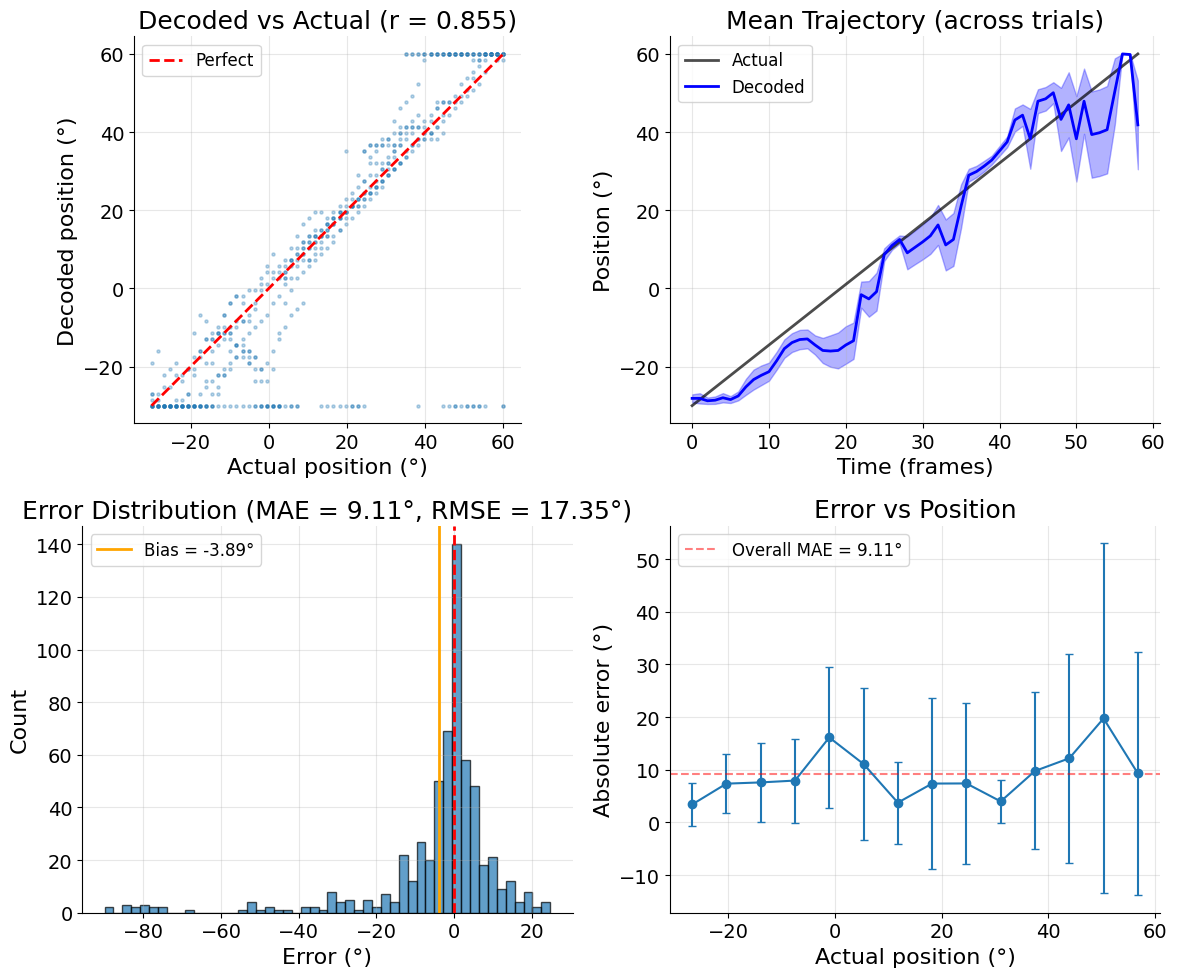

In [124]:
actual_positions = np.tile(R.angle_range, (len(decoded_positions))).T
actual_positions = np.squeeze(actual_positions)
decoded_positions = np.squeeze(np.array(decoded_positions))

print(actual_positions.shape)
print(decoded_positions.shape)

fig, metrics = plot_decoder_performance(actual_positions, decoded_positions)
print_metrics(metrics)